<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
Original Features: 4
Reduced Features: 2

Before LDA
Accuracy: 1.0
Execution Time: 0.008971214294433594

After LDA
Accuracy: 1.0
Execution Time: 0.011782407760620117


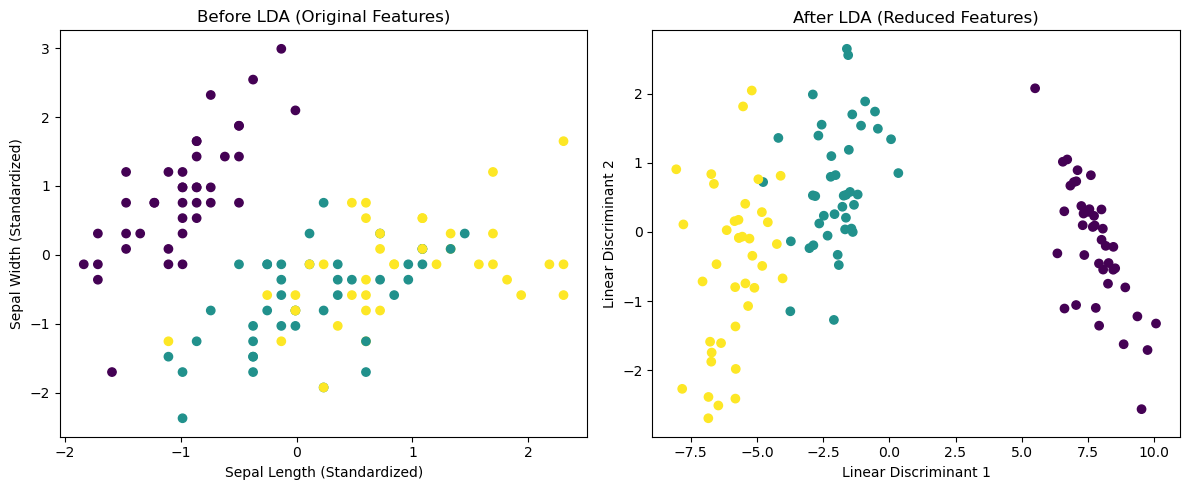

In [32]:
import pandas as pd
import time
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
df = pd.read_csv(r"C:\Users\HP\Downloads\iris.csv")


df.head()

df.info()

df.isnull().sum().sum()

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


start = time.time()
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)
time1 = time.time() - start
acc1 = accuracy_score(y_test, pred)

lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)


start = time.time()
model_lda = LogisticRegression(max_iter=1000)
model_lda.fit(X_train_lda, y_train)
pred_lda = model_lda.predict(X_test_lda)
time2 = time.time() - start
acc2 = accuracy_score(y_test, pred_lda)


print("Original Features:", X.shape[1])
print("Reduced Features:", X_train_lda.shape[1])


print("\nBefore LDA")
print("Accuracy:", acc1)
print("Execution Time:", time1)


print("\nAfter LDA")
print("Accuracy:", acc2)
print("Execution Time:", time2)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap='viridis'
)

plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.title("Before LDA (Original Features)")

# After LDA
plt.subplot(1, 2, 2)

plt.scatter(
    X_train_lda[:, 0],
    X_train_lda[:, 1],
    c=y_train
   
)

plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("After LDA (Reduced Features)")

plt.tight_layout()
plt.show()



